# Entregable 2: datos y exploración

Riesgo de los commits del kernel de Linux con un clasificador difuso-evolutivo. Juan Felipe Rodríguez Galindo (20261595004), Inteligencia Computacional, MCIC-UD.

Este cuaderno reproduce las Tablas IV y V y las Figs. 3 y 4 del artículo a partir de la tabla anonimizada de commits. **Primero se reserva la prueba (2026)** y toda la exploración usa solo el desarrollo (2019-2025).

In [1]:
# Parámetros
ARCHIVO = "datos/juan-rodriguez-20261595004-kernel-commits-2019-2026.parquet"
INICIO, INICIO_PRUEBA, FIN_PRUEBA = "2019-01-01", "2026-01-01", "2026-08-01"
UMBRAL_CORRELACION = 0.7


In [2]:
import platform
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)
plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.spines.top": False, "axes.spines.right": False})
AZUL, PLATA = "#1291C0", "#98999A"

Python 3.13.15 | pandas 3.1.1 | numpy 2.5.4 | matplotlib 3.11.2


## 1. Carga y reserva de la prueba

Se quitan los commits censurados (menos de 90 días de observación) y se separa la prueba. De la prueba solo se cuenta el tamaño.

In [3]:
df = pd.read_parquet(ARCHIVO)
print("filas en la tabla:", len(df), "| censurados:", int(df.censurado.sum()))
obs = df[~df.censurado].sort_values("t_commit", kind="stable").reset_index(drop=True)
ts = lambda x: pd.Timestamp(x, tz="UTC")
dev = obs[(obs.fecha >= ts(INICIO)) & (obs.fecha < ts(INICIO_PRUEBA))]
n_prueba = int(((obs.fecha >= ts(INICIO_PRUEBA)) & (obs.fecha < ts(FIN_PRUEBA))).sum())
del obs   # a partir de aquí solo se usa el desarrollo
print(f"desarrollo 2019-2025: {len(dev):,} | prueba 2026 (solo el conteo): {n_prueba:,}")

filas en la tabla: 641926 | censurados: 26133


desarrollo 2019-2025: 558,438 | prueba 2026 (solo el conteo): 54,373


## 2. Diccionario de variables (Tabla A1)

In [4]:
DICCIONARIO = {
 "lineas_add": ("tamaño", "Líneas añadidas por el commit (numstat)", "líneas"),
 "lineas_del": ("tamaño", "Líneas borradas", "líneas"),
 "n_archivos": ("tamaño", "Archivos modificados", "archivos"),
 "n_binarios": ("tamaño", "Archivos binarios modificados", "archivos"),
 "n_dirs_raiz": ("difusión", "Directorios de primer nivel tocados", "directorios"),
 "n_subsistemas": ("difusión", "Subsistemas tocados (dos primeros niveles de ruta)", "subsistemas"),
 "n_reviewed": ("revisión", "Trailers Reviewed-by", "trailers"),
 "n_acked": ("revisión", "Trailers Acked-by", "trailers"),
 "n_tested": ("revisión", "Trailers Tested-by", "trailers"),
 "n_reported": ("revisión", "Trailers Reported-by", "trailers"),
 "n_signed": ("revisión", "Trailers Signed-off-by (cadena de integración)", "trailers"),
 "n_codev": ("revisión", "Trailers Co-developed-by", "trailers"),
 "n_link": ("revisión", "Trailers Link (hilo de la lista de correo)", "trailers"),
 "cc_stable": ("propósito", "1 si pide backport (Cc: stable)", "0/1"),
 "es_fix": ("propósito", "1 si trae su propio Fixes: (es una corrección)", "0/1"),
 "asunto_fix": ("propósito", "1 si el asunto contiene fix", "0/1"),
 "len_asunto": ("propósito", "Longitud del asunto", "caracteres"),
 "exp_autor": ("experiencia", "Commits previos del autor (desde 2014)", "commits"),
 "dias_desde_primer_commit": ("experiencia", "Días desde el primer commit del autor", "días"),
 "exp_autor_subsistema": ("experiencia", "Commits previos del autor en el subsistema", "commits"),
 "hora_utc": ("momento", "Hora UTC de la fecha de autor", "hora"),
 "dia_semana": ("momento", "Día de la semana (0 = lunes)", "día"),
}
VARIABLES = list(DICCIONARIO)
pd.DataFrame(DICCIONARIO, index=["familia", "descripción", "unidad"]).T

,familia,descripción,unidad
lineas_add,tamaño,Líneas añadidas por el commit (numstat),líneas
lineas_del,tamaño,Líneas borradas,líneas
n_archivos,tamaño,Archivos modificados,archivos
n_binarios,tamaño,Archivos binarios modificados,archivos
n_dirs_raiz,difusión,Directorios de primer nivel tocados,directorios
n_subsistemas,difusión,Subsistemas tocados (dos primeros niveles de r...,subsistemas
n_reviewed,revisión,Trailers Reviewed-by,trailers
n_acked,revisión,Trailers Acked-by,trailers
n_tested,revisión,Trailers Tested-by,trailers
n_reported,revisión,Trailers Reported-by,trailers


## 3. Verificación D1-D7 (Tabla IV)

In [5]:
anual = dev.groupby(dev.fecha.dt.year)["riesgoso"]
gaps_h = dev.t_commit.diff().dropna() / 3600
d1d7 = {
 "D1 tamaño": f"{len(dev) + n_prueba:,} commits ({len(dev):,} desarrollo, {n_prueba:,} prueba)",
 "D2 objetivo": f"{int(dev.riesgoso.sum()):,} positivos; prevalencia {anual.mean().min():.2%}-{anual.mean().max():.2%}",
 "D3 calidad": f"faltantes objetivo {dev.riesgoso.isna().mean():.1%}; faltantes entradas {dev[VARIABLES].isna().mean().max():.1%}; hashes duplicados {int(df.hash.duplicated().sum())}",
 "D4 estructura": f"orden por fecha del committer; mediana {gaps_h.median():.2f} h entre commits; {dev.autor.nunique():,} autores y {dev.subsistema.nunique():,} subsistemas",
 "D5 disponibilidad": "solo el propio commit y el pasado del autor",
 "D6 licencia y ética": "GPL-2.0; autores con SHA-256 con sal: columnas " + str(sorted(set(df.columns) & {"email", "nombre"})),
 "D7 documentación": f"diccionario de {len(VARIABLES)} variables (celda anterior)",
}
pd.Series(d1d7).to_frame("evidencia")

,evidencia
D1 tamaño,"612,811 commits (558,438 desarrollo, 54,373 pr..."
D2 objetivo,"23,735 positivos; prevalencia 3.89%-4.47%"
D3 calidad,faltantes objetivo 0.0%; faltantes entradas 0....
D4 estructura,orden por fecha del committer; mediana 0.00 h ...
D5 disponibilidad,solo el propio commit y el pasado del autor
D6 licencia y ética,GPL-2.0; autores con SHA-256 con sal: columnas []
D7 documentación,diccionario de 22 variables (celda anterior)


### D3: el mismo parche dos veces (*cherry-picks*)

Esta revisión necesita el clon completo del kernel (`src/e2_backports.py`), así que aquí va su resultado incrustado. Se comprueba contra la tabla que las cifras sean coherentes.

In [6]:
BACKPORTS = {
 "commits_con_marca_cherry_pick": 2345,
 "pares_ambas_copias_en_desarrollo": 2305,
 "fraccion_del_desarrollo": 0.004127584440886903,
 "pares_por_anio": {
  "2019": 201,
  "2020": 263,
  "2021": 205,
  "2022": 206,
  "2023": 198,
  "2024": 556,
  "2025": 676
 },
 "dias_entre_copias_mediana": 3.0,
 "dias_entre_copias_max": 75.0,
 "etiquetas_concordantes": 2227,
 "etiquetas_discordantes": 78,
 "decision": "Se conservan ambas copias. Las dos copias distan pocos días, así que casi siempre caen en el mismo bloque temporal, y las etiquetas discordantes son una fracción mínima del desarrollo, muy por debajo del ruido propio de la etiqueta Fixes: (81 % de culpables confirmados)."
}
print(f"pares en desarrollo: {BACKPORTS['pares_ambas_copias_en_desarrollo']:,} "
      f"({BACKPORTS['pares_ambas_copias_en_desarrollo'] / len(dev):.2%} del desarrollo); "
      f"etiquetas discordantes: {BACKPORTS['etiquetas_discordantes']}")

pares en desarrollo: 2,305 (0.41% del desarrollo); etiquetas discordantes: 78


## 4. Estadísticos descriptivos (Tabla V)

In [7]:
desc = pd.DataFrame({
 "unidad": [DICCIONARIO[v][2] for v in VARIABLES],
 "media": dev[VARIABLES].mean(), "DE": dev[VARIABLES].std(),
 "mín.": dev[VARIABLES].min(), "mediana": dev[VARIABLES].median(),
 "p99": dev[VARIABLES].quantile(0.99), "máx.": dev[VARIABLES].max(),
 "% falt.": 100 * dev[VARIABLES].isna().mean()}, index=VARIABLES)
desc.round(3)

,unidad,media,DE,mín.,mediana,p99,máx.,% falt.
lineas_add,líneas,59.193,1575.633,0.0,7.000,645.000,730092.000,0.0
lineas_del,líneas,30.865,1233.563,0.0,3.000,282.000,729826.000,0.0
n_archivos,archivos,2.160,12.297,0.0,1.000,14.000,5257.000,0.0
n_binarios,archivos,0.000,0.005,0.0,0.000,0.000,2.000,0.0
n_dirs_raiz,directorios,1.113,0.409,0.0,1.000,3.000,15.000,0.0
n_subsistemas,subsistemas,1.167,1.201,0.0,1.000,4.000,369.000,0.0
n_reviewed,trailers,0.539,0.749,0.0,0.000,3.000,17.000,0.0
n_acked,trailers,0.177,0.465,0.0,0.000,2.000,36.000,0.0
n_tested,trailers,0.085,0.342,0.0,0.000,1.000,8.000,0.0
n_reported,trailers,0.068,0.279,0.0,0.000,1.000,11.000,0.0


## 5. Variable objetivo (Fig. 3)

Balance de clases por año (solo 2019-2025) y tamaño por clase. La tabla trae desde 2019; la figura del artículo añade 2014-2018 desde el clon para mostrar la adopción de `Fixes:`.

fecha
2019    4.27
2020    4.41
2021    4.47
2022    4.32
2023    3.89
2024    4.14
2025    4.27


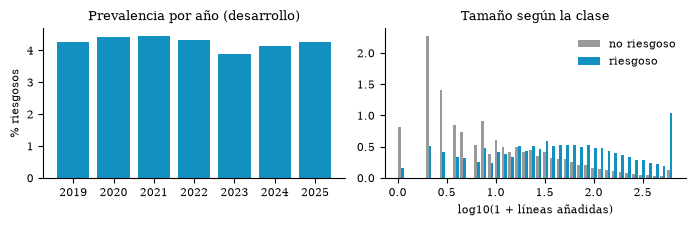

In [8]:
prev = anual.mean()
print((prev * 100).round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(7, 2.3))
ax[0].bar(prev.index, prev.values * 100, color=AZUL)
ax[0].set_ylabel("% riesgosos"); ax[0].set_title("Prevalencia por año (desarrollo)")
x = dev.lineas_add.clip(upper=dev.lineas_add.quantile(0.99))
ax[1].hist([np.log10(1 + x[dev.riesgoso == 0]), np.log10(1 + x[dev.riesgoso == 1])], bins=40,
           density=True, color=[PLATA, AZUL], label=["no riesgoso", "riesgoso"])
ax[1].set_xlabel("log10(1 + líneas añadidas)"); ax[1].legend(frameon=False)
ax[1].set_title("Tamaño según la clase"); fig.tight_layout(); plt.show()

In [9]:
quintil = {v: dev.groupby(pd.qcut(dev[v].rank(method="first"), 5, labels=False))["riesgoso"].mean()
           for v in VARIABLES}
q = pd.DataFrame(quintil).T.mul(100).round(2)
q.columns = [f"Q{i + 1}" for i in range(5)]
q   # prevalencia (%) por quintil de cada variable

,Q1,Q2,Q3,Q4,Q5
lineas_add,0.94,1.50,2.51,4.61,11.69
lineas_del,4.90,2.52,2.90,4.02,6.91
n_archivos,2.54,2.58,2.39,4.22,9.51
n_binarios,4.37,4.38,4.33,3.93,4.24
n_dirs_raiz,3.64,3.75,3.58,3.37,6.92
n_subsistemas,3.61,3.71,3.54,3.35,7.03
n_reviewed,4.30,4.34,4.10,4.32,4.19
n_acked,4.30,4.38,4.03,4.25,4.29
n_tested,4.33,4.29,4.11,3.84,4.68
n_reported,4.33,4.40,4.23,3.94,4.35


## 6. Correlaciones de Spearman (Fig. 4)

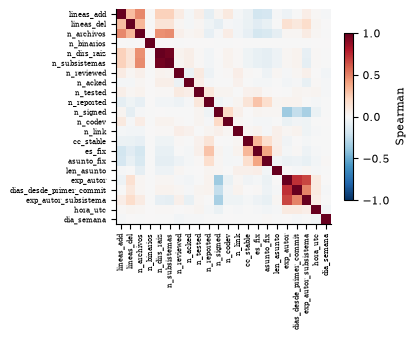

[('n_dirs_raiz', 'n_subsistemas', np.float64(0.967)),
 ('exp_autor', 'dias_desde_primer_commit', np.float64(0.728))]

In [10]:
corr = dev[VARIABLES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(4.2, 3.6))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(VARIABLES)), VARIABLES, rotation=90, fontsize=5)
ax.set_yticks(range(len(VARIABLES)), VARIABLES, fontsize=5)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman"); fig.tight_layout(); plt.show()
altas = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(VARIABLES) for b in VARIABLES[i + 1:]
         if abs(corr.loc[a, b]) >= UMBRAL_CORRELACION]
altas

## 7. Deriva de las covariables (2019-2025)

In [11]:
dev.groupby(dev.fecha.dt.year)[["lineas_add", "n_archivos", "n_reviewed", "es_fix", "cc_stable", "exp_autor"]].mean().round(3)

,lineas_add,n_archivos,n_reviewed,es_fix,cc_stable,exp_autor
fecha,,,,,,
2019,56.700,2.420,0.421,0.145,0.046,523.699
2020,60.423,2.183,0.426,0.152,0.044,565.735
2021,51.762,2.034,0.438,0.168,0.048,599.470
2022,74.582,2.115,0.538,0.178,0.045,590.941
2023,66.478,2.190,0.597,0.163,0.049,772.133
2024,51.461,2.108,0.649,0.187,0.060,814.682
2025,51.966,2.071,0.710,0.184,0.061,826.745


## 8. Hallazgos y decisiones

- La prevalencia es estable desde 2019 → el entrenamiento empieza el 1 de enero de 2019.
- Clases desbalanceadas (~4 %) → métrica principal AUC-PR, sin remuestreo.
- El tamaño es la señal dominante y no lineal, con colas extremas → transformación por cuantiles (difuso) y log(1+x) estandarizado (logística), ajustados solo con el entrenamiento.
- `n_dirs_raiz`~`n_subsistemas` y `exp_autor`~`dias_desde_primer_commit` → el difuso usa uno de cada par.
- Deriva en `n_reviewed` y `es_fix` → validación por ventanas temporales, no validación cruzada aleatoria.